知识点：
1. dataloader
2. dataset
3. bitchsize


# 导入库

In [15]:
import torch
import torch.nn as nn
import torch.optim as optim
from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
import numpy as np
from torch.utils.data import DataLoader, TensorDataset

# 加载dataloader
只要知道这部分的目的就是把数据划分成批次加载就可以了

In [16]:
def data_loader(data, label, batch_size=24, mode="train"):
    data_tensor = torch.tensor(data, dtype=torch.float32)
    label_tensor = torch.tensor(label, dtype=torch.int64)
    dataset = TensorDataset(data_tensor, label_tensor)
    if mode == "train":
        shuffle = True
    else:
        shuffle = False
    return DataLoader(dataset, batch_size=batch_size, shuffle=shuffle)

In [17]:
# 加载鸢尾花数据集
iris = load_iris()
X = iris.data
y = iris.target
# 划分训练集和测试集
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

In [18]:
# 标准化数据
from sklearn.preprocessing import StandardScaler
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

In [19]:
# 创建数据加载器
train_loader = data_loader(X_train, y_train, batch_size=10, mode="train")
test_loader = data_loader(X_test, y_test, batch_size=10, mode="test")

# 构建网络结构


In [20]:
class IrisNet(nn.Module):
    def __init__(self):
        super(IrisNet, self).__init__()
        self.fc1 = nn.Linear(4, 10)
        self.relu = nn.ReLU()
        self.fc2 = nn.Linear(10, 3)

    def forward(self, x):
        out = self.fc1(x)
        out = self.relu(out)
        out = self.fc2(out)
        return out
    
# 初始化模型
model = IrisNet()

# 打印每个epoch的损失

In [ ]:
# 分类问题使用交叉熵损失函数
criterion = nn.CrossEntropyLoss()
# 使用随机梯度下降优化器
optimizer = optim.SGD(model.parameters(), lr=0.01)

# 训练模型
num_epochs = 1000
# 用于存储每个 epoch 的损失值
losses = []



for epoch in range(num_epochs):
    running_loss = 0.0
    for i, (inputs, labels) in enumerate(train_loader):
        # 前向传播
        outputs = model(inputs)
        loss = criterion(outputs, labels)

        # 反向传播和优化
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

        running_loss += loss.item()

    epoch_loss = running_loss / len(train_loader)
    losses.append(epoch_loss)

    # 打印训练信息
    if (epoch + 1) % 100 == 0:
        print(f'Epoch [{epoch + 1}/{num_epochs}], Loss: {epoch_loss:.4f}')

Epoch [100/1000], Loss: 0.2520
Epoch [200/1000], Loss: 0.1379
Epoch [300/1000], Loss: 0.0961
Epoch [400/1000], Loss: 0.0784
Epoch [500/1000], Loss: 0.0697
Epoch [600/1000], Loss: 0.0642
Epoch [700/1000], Loss: 0.0606
Epoch [800/1000], Loss: 0.0576
Epoch [900/1000], Loss: 0.0560
Epoch [1000/1000], Loss: 0.0548


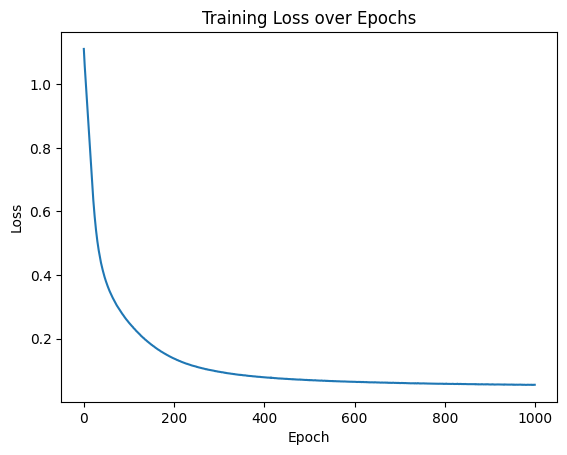

In [22]:
import matplotlib.pyplot as plt
# 可视化损失曲线
plt.plot(range(num_epochs), losses)
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.title('Training Loss over Epochs')
plt.show()

# 打印每个bitchsize的损失

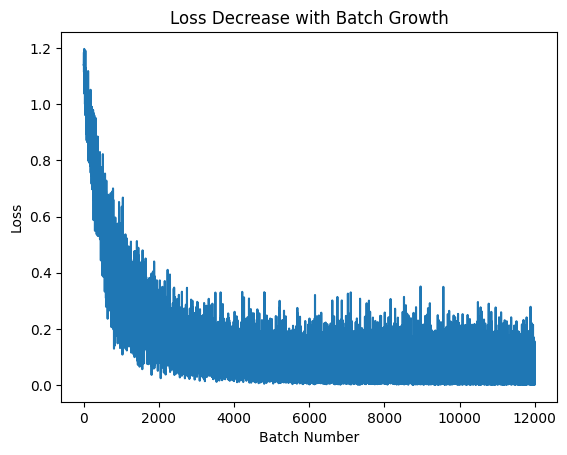

In [24]:
import torch
import torch.nn as nn
import torch.optim as optim
from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
import numpy as np
from torch.utils.data import DataLoader, TensorDataset
import matplotlib.pyplot as plt


def data_loader(data, label, batch_size = 24, mode = "train"):
    data_tensor = torch.tensor(data, dtype = torch.float32)
    label_tensor = torch.tensor(label, dtype = torch.int64)
    dataset = TensorDataset(data_tensor, label_tensor)
    if mode == "train":
        shuffle = True
    else:
        shuffle = False
    return DataLoader(dataset, batch_size = batch_size, shuffle = shuffle)


# 加载鸢尾花数据集
iris = load_iris()
X = iris.data
y = iris.target
# 划分训练集和测试集
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size = 0.2, random_state = 42)

# 标准化数据
from sklearn.preprocessing import StandardScaler
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

# 创建数据加载器
train_loader = data_loader(X_train, y_train, batch_size = 10, mode = "train")
test_loader = data_loader(X_test, y_test, batch_size = 10, mode = "test")


class IrisNet(nn.Module):
    def __init__(self):
        super(IrisNet, self).__init__()
        self.fc1 = nn.Linear(4, 10)
        self.relu = nn.ReLU()
        self.fc2 = nn.Linear(10, 3)

    def forward(self, x):
        out = self.fc1(x)
        out = self.relu(out)
        out = self.fc2(out)
        return out


# 初始化模型
model = IrisNet()
# 分类问题使用交叉熵损失函数
criterion = nn.CrossEntropyLoss()
# 使用随机梯度下降优化器
optimizer = optim.SGD(model.parameters(), lr = 0.01)

# 训练模型
num_epochs = 1000
# 存储每个批次的损失
batch_losses = []
batch_count = 0

for epoch in range(num_epochs):
    for i, (inputs, labels) in enumerate(train_loader):
        batch_count += 1
        # 前向传播
        outputs = model(inputs)
        loss = criterion(outputs, labels)

        # 反向传播和优化
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

        batch_losses.append(loss.item())


# 绘制损失随批次增长的图
plt.plot(range(batch_count), batch_losses)
plt.xlabel('Batch Number')
plt.ylabel('Loss')
plt.title('Loss Decrease with Batch Growth')
plt.show()


In [25]:
# 在测试集上评估模型
model.eval()
correct = 0
total = 0
with torch.no_grad():
    for inputs, labels in test_loader:
        outputs = model(inputs)
        _, predicted = torch.max(outputs.data, 1)
        total += labels.size(0)
        correct += (predicted == labels).sum().item()

print(f'Accuracy on test set: {100 * correct / total}%')

Accuracy on test set: 100.0%
